# 极客项目 ch02：万花尺 Spirograph

对应《Python Playground》第 2 章（Spirographs）。turtle 部分**需本地图形界面**，本 notebook 保留代码但不执行；数学部分用 matplotlib 固定种子（2025）复现。

In [1]:
# ===== 公共设置 =====
%matplotlib inline
import math
import random
import numpy as np
import matplotlib.pyplot as plt
import turtle                          # 仅导入不弹窗；实例化 Turtle 需本地图形界面

random.seed(2025)
np.random.seed(2025)
plt.rcParams["font.sans-serif"] = ["Microsoft YaHei"]
plt.rcParams["axes.unicode_minus"] = False


## 书 2.1.1 万花尺方程

$k = r/R$（半径比），$l = PC/r$（笔位比）：

$$x = R\left[(1-k)\cos\theta + lk\cos\left(\frac{(1-k)\theta}{k}\right)\right],\qquad
y = R\left[(1-k)\sin\theta - lk\sin\left(\frac{(1-k)\theta}{k}\right)\right]$$

周期：$n_{Rot} = r/\gcd(r,R)$ 圈后闭合，花瓣数 $R/\gcd(r,R)$。

## 演示：matplotlib 复现螺线

turtle 窗口无头环境跑不了，用同一参数方程出图；参数按 `SpiroAnimator.genRandomParams()` 的分布随机取（seed=2025）。

R=192 r= 31 l=0.62 -> nRot=31（花瓣 192）
R=172 r= 54 l=0.52 -> nRot=27（花瓣 86）
R=145 r= 58 l=0.56 -> nRot=2（花瓣 5）
R= 66 r= 34 l=0.42 -> nRot=17（花瓣 33）


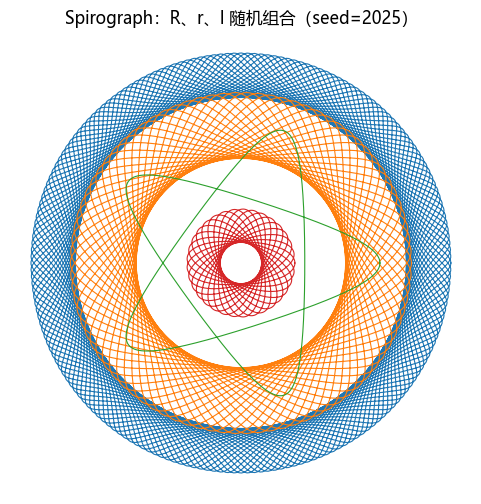

In [2]:
# ===== 演示：matplotlib 复现万花尺螺线（书 2.1.1 方程）=====
random.seed(2025)

def spiro_xy(R, r, l, nPts=6000):
    """书 2.1.1 节参数方程；nRot = r//gcd(r, R) 决定画到几圈"""
    k = r/float(R)
    nRot = r//math.gcd(r, R)
    a = np.linspace(0, 2*np.pi*nRot, nPts)
    x = R*((1-k)*np.cos(a) + l*k*np.cos((1-k)*a/k))
    y = R*((1-k)*np.sin(a) - l*k*np.sin((1-k)*a/k))
    return x, y, nRot

fig, ax = plt.subplots(figsize=(6, 6))
for i in range(4):
    R = random.randint(50, 200)
    r = random.randint(10, 9*R//10)
    l = random.uniform(0.1, 0.9)
    x, y, nRot = spiro_xy(R, r, l)
    ax.plot(x, y, lw=0.8)
    print('R=%3d r=%3d l=%.2f -> nRot=%d（花瓣 %d）' % (R, r, l, nRot, R//math.gcd(r, R)))
ax.set_aspect('equal')
ax.axis('off')
ax.set_title('Spirograph：R、r、l 随机组合（seed=2025）')
plt.show()

## 书 2.1.2–2.3.11 turtle 代码（不执行）

> **turtle 需本地图形界面运行**：以下 cell（画圆热身、`Spiro`、`SpiroAnimator`、`saveDrawing`）都会弹出 tkinter 窗口，无头环境跳过执行（标签 `skip-execution`），代码完整保留。书 2.3.12 的 argparse 与 `turtle.mainloop()` 属脚本形态，不进 notebook。

In [ ]:
# ===== 书 2.1.2 节 drawcircle.py（不执行：需本地图形界面）=====
import math
import turtle

# draw the circle using turtle
def drawCircleTurtle(x, y, r):
    # move to the start of circle
    turtle.up()                    # 提笔：笔离开"纸"，移动不画线
    turtle.setpos(x + r, y)        # 移到起点 (x+r, y)——(x, y) 是圆心，起点在圆的最右端
    turtle.down()                  # 落笔：准备画图

    # draw the circle
    for i in range(0, 365, 5):     # 角度 i 以 5 为步长，从 0 到 360
        a = math.radians(i)        # 度转弧度（计算机角度计算大多需要弧度）
        # 参数方程算出圆上的下一个点，海龟从上一位置画线到新位置
        turtle.setpos(x + r*math.cos(a), y + r*math.sin(a))

drawCircleTurtle(100, 100, 50)     # 圆心 (100, 100)，半径 50
turtle.mainloop()                  # 保持 tkinter 窗口打开

In [ ]:
# ===== 书 2.3.1–2.3.5 节 Spiro 类 =====
# 画万花尺的类
class Spiro:
    def __init__(self, xc, yc, col, R, r, l):
        # 自己的画笔
        self.t = turtle.Turtle()
        self.t.shape('turtle')
        self.step = 5
        self.drawingComplete = False
        self.setparams(xc, yc, col, R, r, l)
        self.restart()

    def setparams(self, xc, yc, col, R, r, l):
        self.xc = xc
        self.yc = yc
        self.R = int(R)
        self.r = int(r)
        self.l = l
        self.col = col
        # 约去 r/R 后的圈数
        gcdVal = math.gcd(self.r, self.R)  # Py3：fractions.gcd→math.gcd
        self.nRot = self.r//gcdVal
        # 半径比
        self.k = r/float(R)
        self.t.color(*col)
        self.a = 0

    def restart(self):
        self.drawingComplete = False
        self.t.showturtle()
        self.t.up()
        R, k, l = self.R, self.k, self.l
        a = 0.0
        x = R*((1-k)*math.cos(a) + l*k*math.cos((1-k)*a/k))
        y = R*((1-k)*math.sin(a) - l*k*math.sin((1-k)*a/k))
        self.t.setpos(self.xc + x, self.yc + y)
        self.t.down()

    def draw(self):
        R, k, l = self.R, self.k, self.l
        for i in range(0, 360*self.nRot + 1, self.step):
            a = math.radians(i)
            x = R*((1-k)*math.cos(a) + l*k*math.cos((1-k)*a/k))
            y = R*((1-k)*math.sin(a) - l*k*math.sin((1-k)*a/k))
            self.t.setpos(self.xc + x, self.yc + y)
        self.t.hideturtle()

    def update(self):
        if self.drawingComplete:
            return
        self.a += self.step
        R, k, l = self.R, self.k, self.l
        a = math.radians(self.a)
        x = self.R*((1-k)*math.cos(a) + l*k*math.cos((1-k)*a/k))
        y = self.R*((1-k)*math.sin(a) - l*k*math.sin((1-k)*a/k))
        self.t.setpos(self.xc + x, self.yc + y)
        if self.a >= 360*self.nRot:
            self.drawingComplete = True
            self.t.hideturtle()

    def clear(self):
        self.t.clear()


In [ ]:
# ===== 书 2.3.6–2.3.10 节 SpiroAnimator 类 =====
# 动画类
class SpiroAnimator:
    def __init__(self, N):
        self.deltaT = 10  # ms
        self.width = turtle.window_width()
        self.height = turtle.window_height()
        self.spiros = []
        for i in range(N):
            rparams = self.genRandomParams()
            spiro = Spiro(*rparams)
            self.spiros.append(spiro)

    def restart(self):
        for spiro in self.spiros:
            spiro.clear()
            rparams = self.genRandomParams()
            spiro.setparams(*rparams)
            spiro.restart()

    def genRandomParams(self):
        width, height = self.width, self.height
        R = random.randint(50, min(width, height)//2)
        r = random.randint(10, 9*R//10)
        l = random.uniform(0.1, 0.9)
        xc = random.randint(-width//2, width//2)
        yc = random.randint(-height//2, height//2)
        col = (random.random(), random.random(), random.random())
        return (xc, yc, col, R, r, l)

    def update(self):
        nComplete = 0
        for spiro in self.spiros:
            spiro.update()
            if spiro.drawingComplete:
                nComplete += 1
        # 全部画完则换一组参数重来
        if nComplete == len(self.spiros):
            self.restart()
        turtle.ontimer(self.update, self.deltaT)

    def toggleTurtles(self):
        for spiro in self.spiros:
            if spiro.t.isvisible():
                spiro.t.hideturtle()
            else:
                spiro.t.showturtle()


In [ ]:
# ===== 书 2.3.11 节 saveDrawing() =====
def saveDrawing():
    turtle.hideturtle()
    dateStr = (datetime.now()).strftime("%d%b%Y-%H%M%S")
    fileName = 'spiro-' + dateStr
    print('saving drawing to %s.eps/png' % fileName)
    canvas = turtle.getcanvas()
    canvas.postscript(file=fileName + '.eps')
    # PIL 把 EPS 转成 PNG
    img = Image.open(fileName + '.eps')
    img.save(fileName + '.png', 'png')
    turtle.showturtle()
